<a href="https://colab.research.google.com/github/FunGrape/Labs_ML_Demchyshyn/blob/main/%D0%9B%D0%A02_1_%D0%94%D0%B5%D0%BC%D1%87%D0%B8%D1%88%D0%B8%D0%BD_4_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Лабораторна робота 2. Демчишин, ФІТ 4-9

---



# Завдання 1

**Був присутній на парі**

Обробка та нааліз даних про ВВП країн. Датасет було отримано з Вікіпедії з використанням бібілотеки Pandas.

1. Вивести перші 5 рядків датасета

In [ ]:
import numpy as np
import pandas as pd
import requests

In [ ]:
url = "https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)"
html = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}).text

tables = pd.read_html(html)   # зчитати всі таблиці
df = tables[2]                # потрібна таблиця (може змінюватись!), номери не є сталими!
df.head()

/tmp/ipykernel_2636/3107767188.py:4: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(html)   # зчитати всі таблиці


,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,128003776,118350166,111565144
1,United States,32642373,30769700,29298000
2,China[n 1],21546403,19498039,18743802
3,Germany,5471299,5050923,4659929
4,Japan,4341986,4435163,4026211


2.	Визначити розмір датасета.

In [ ]:
print("Розмір датасета (рядків, стовпців):", df.shape)

Розмір датасета (рядків, стовпців): (222, 4)


 3.	Визначити оптимальну кількість стовпців (видалити зайві, на власний розсуд).

In [ ]:
df.columns = [" ".join(dict.fromkeys(str(x) for x in c)).strip() if isinstance(c, tuple) else str(c)
              for c in df.columns]
print(list(df.columns))

country_col = [c for c in df.columns if "Country" in c][0]
imf_col = [c for c in df.columns if "IMF" in c and "Year" not in c][0]
wb_col = [c for c in df.columns if "World Bank" in c and "Year" not in c][0]
un_col = [c for c in df.columns if "United Nations" in c and "Year" not in c][0]

df = df[[country_col, imf_col, wb_col, un_col]].copy()
df.columns = ["Country", "IMF (2026)", "World Bank (2025)", "United Nations (2024)"]
cols = ["IMF (2026)", "World Bank (2025)", "United Nations (2024)"]

df["Country"] = df["Country"].astype(str).str.replace(r"\[.*?\]", "", regex=True).str.strip()
df = df[df["Country"] != "World"].reset_index(drop=True)
df.head()

['Country/Territory', 'IMF (2026)[1]', 'World Bank (2025)[6]', 'United Nations (2024)[7]']


,Country,IMF (2026),World Bank (2025),United Nations (2024)
0,United States,32642373,30769700,29298000
1,China,21546403,19498039,18743802
2,Germany,5471299,5050923,4659929
3,Japan,4341986,4435163,4026211
4,United Kingdom,4268446,4002588,3685881


4.	Замініть у таблиці значення "—" на значення NaN. Перевірити наявність пропущених значень. При наявності, замінити пропущені значення на середнє значення.

In [ ]:
df = df.replace(["—", "–", "-"], np.nan)
for c in cols:
    df[c] = pd.to_numeric(
        df[c].astype(str).str.replace(r"\[.*?\]", "", regex=True).str.replace(",", "").str.strip(),
        errors="coerce")
df.dtypes

,0
Country,object
IMF (2026),float64
World Bank (2025),float64
United Nations (2024),float64


In [ ]:
df.isna().sum()

,0
Country,0
IMF (2026),30
World Bank (2025),35
United Nations (2024),9


In [ ]:
df[cols] = df[cols].fillna(df[cols].mean())

In [ ]:
df.isna().sum()

,0
Country,0
IMF (2026),0
World Bank (2025),0
United Nations (2024),0


5. Ще раз вивести датасет

In [ ]:
df

,Country,IMF (2026),World Bank (2025),United Nations (2024)
0,United States,3.264237e+07,3.076970e+07,29298000.0
1,China,2.154640e+07,1.949804e+07,18743802.0
2,Germany,5.471299e+06,5.050923e+06,4659929.0
3,Japan,4.341986e+06,4.435163e+06,4026211.0
4,United Kingdom,4.268446e+06,4.002588e+06,3685881.0
...,...,...,...,...
216,Palau,3.770000e+02,3.450000e+02,310.0
217,Marshall Islands,3.420000e+02,3.080000e+02,281.0
218,Nauru,1.960000e+02,1.760000e+02,187.0
219,Montserrat,6.690289e+05,6.260497e+05,81.0


6.	Перевірити наявність дублікатів. При наявності видалити дублікати.

In [ ]:
print("Дублікатів (повні рядки):", df.duplicated().sum())

Дублікатів (повні рядки): 0


In [ ]:
print("Дублікатів за назвою країни:", df["Country"].duplicated().sum())

Дублікатів за назвою країни: 0


In [ ]:
df = df.drop_duplicates().drop_duplicates(subset="Country").reset_index(drop=True)
print("Після видалення:", df.duplicated().sum(), "| розмір:", df.shape)

Після видалення: 0 | розмір: (221, 4)


7.	Вивести описову статистику датасету describe()

In [ ]:
df[cols].describe()

,IMF (2026),World Bank (2025),United Nations (2024)
count,2.210000e+02,2.210000e+02,2.210000e+02
mean,6.690289e+05,6.260497e+05,5.224912e+05
std,2.705629e+06,2.520399e+06,2.410079e+06
min,6.500000e+01,5.700000e+01,5.600000e+01
25%,1.895900e+04,1.992800e+04,8.840000e+03
50%,1.020420e+05,9.977400e+04,4.276500e+04
75%,6.690289e+05,6.260497e+05,2.986970e+05
max,3.264237e+07,3.076970e+07,2.929800e+07


8. Визначте відхилення (різницю) між показниками IMF (2026) та World Bank (2025) для кожної країни. У яких країнах ці показники найбільше відрізняються (дати відповідь)?

In [ ]:
df["Відхилення IMF-WB"] = df["IMF (2026)"] - df["World Bank (2025)"]
df["Відхилення (модуль)"] = df["Відхилення IMF-WB"].abs()

top = df.sort_values("Відхилення (модуль)", ascending=False).head(10)
display(top[["Country", "IMF (2026)", "World Bank (2025)", "Відхилення IMF-WB"]])
print("Відповідь: найбільше відрізняються:", ", ".join(top["Country"].head(5)))

,Country,IMF (2026),World Bank (2025),Відхилення IMF-WB
1,China,2.154640e+07,1.949804e+07,2.048364e+06
0,United States,3.264237e+07,3.076970e+07,1.872673e+06
196,Sint Maarten,6.690289e+05,1.888000e+03,6.671409e+05
145,Palestine,6.690289e+05,1.716700e+04,6.518619e+05
191,San Marino,2.417000e+03,6.260497e+05,-6.236327e+05
178,Aruba,4.671000e+03,6.260497e+05,-6.213787e+05
171,South Sudan,6.069000e+03,6.260497e+05,-6.199807e+05
167,Yemen,7.435000e+03,6.260497e+05,-6.186147e+05
158,Liechtenstein,9.442000e+03,6.260497e+05,-6.166077e+05
147,Bahamas,1.704200e+04,6.260497e+05,-6.090077e+05


Відповідь: найбільше відрізняються: China, United States, Sint Maarten, Palestine, San Marino


9.	Обчисліть кореляцію між показниками IMF (2026), World Bank (2025) та United Nations (2024). Які пари змінних мають найвищу кореляцію?

In [ ]:
corr = df[cols].corr()
display(corr)

,IMF (2026),World Bank (2025),United Nations (2024)
IMF (2026),1.000000,0.998462,0.997189
World Bank (2025),0.998462,1.000000,0.997011
United Nations (2024),0.997189,0.997011,1.000000


In [ ]:
mask = np.triu(np.ones(corr.shape), k=1).astype(bool)
pairs = corr.where(mask).stack().sort_values(ascending=False)
display(pairs)
print("Найвища кореляція між", pairs.index[0][0], "та", pairs.index[0][1], "=", round(pairs.iloc[0], 4))

IMF (2026)         World Bank (2025)        0.998462
                   United Nations (2024)    0.997189
World Bank (2025)  United Nations (2024)    0.997011
dtype: float64

Найвища кореляція між IMF (2026) та World Bank (2025) = 0.9985


Обчислити середнє значення за стовпцями

In [ ]:
df[cols].mean()

,0
IMF (2026),669028.937173
World Bank (2025),626049.693548
United Nations (2024),522491.207547


11.	Обчисліть стандартне відхилення показників для кожної країни. Яка країна має найвищу варіативність у показниках між роками?

In [ ]:
df["Std"] = df[cols].std(axis=1)
top_std = df.sort_values("Std", ascending=False).head(10)
display(top_std[["Country"] + cols + ["Std"]])
print("Найвища варіативність у країні:", top_std["Country"].iloc[0])

,Country,IMF (2026),World Bank (2025),United Nations (2024),Std
0,United States,3.264237e+07,3.076970e+07,29298000.0,1.676188e+06
1,China,2.154640e+07,1.949804e+07,18743802.0,1.450244e+06
2,Germany,5.471299e+06,5.050923e+06,4659929.0,4.057737e+05
196,Sint Maarten,6.690289e+05,1.888000e+03,1670.0,3.852369e+05
145,Palestine,6.690289e+05,1.716700e+04,16017.0,3.766851e+05
219,Montserrat,6.690289e+05,6.260497e+05,81.0,3.744274e+05
214,Cook Islands,6.690289e+05,6.260497e+05,414.0,3.742355e+05
213,Anguilla,6.690289e+05,6.260497e+05,456.0,3.742113e+05
200,Turks and Caicos Islands,6.690289e+05,6.260497e+05,1757.0,3.734614e+05
198,British Virgin Islands,6.690289e+05,6.260497e+05,1830.0,3.734193e+05


Найвища варіативність у країні: United States


12.	Визначення країни з найвищим та найнижчим показниками: Знайдіть країну з найвищим та найнижчим показниками у кожному з років (IMF (2026), World Bank (2025), United Nations (2024)).

In [ ]:
for c in cols:
    imax, imin = df[c].idxmax(), df[c].idxmin()
    print(f"{c}:")
    print(f"   найвищий  - {df.loc[imax, 'Country']} ({df.loc[imax, c]:,.0f})")
    print(f"   найнижчий - {df.loc[imin, 'Country']} ({df.loc[imin, c]:,.0f})")

IMF (2026):
   найвищий  - United States (32,642,373)
   найнижчий - Tuvalu (65)
World Bank (2025):
   найвищий  - United States (30,769,700)
   найнижчий - Tuvalu (57)
United Nations (2024):
   найвищий  - United States (29,298,000)
   найнижчий - Tuvalu (56)


13.	Побудуйте гістограму для розподілу показників IMF (2026) серед всіх країн. Який вигляд має розподіл? Чи є країни, що виділяються?

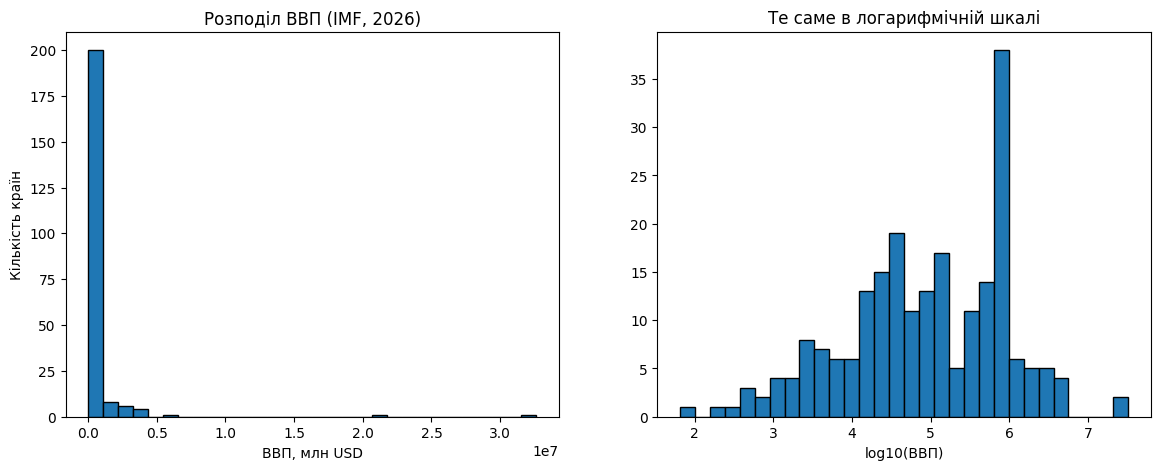

,Country,IMF (2026)
0,United States,32642373.0
1,China,21546403.0
2,Germany,5471299.0
3,Japan,4341986.0
4,United Kingdom,4268446.0


In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].hist(df["IMF (2026)"], bins=30, edgecolor="black")
ax[0].set_title("Розподіл ВВП (IMF, 2026)")
ax[0].set_xlabel("ВВП, млн USD")
ax[0].set_ylabel("Кількість країн")

ax[1].hist(np.log10(df["IMF (2026)"].clip(lower=1)), bins=30, edgecolor="black")
ax[1].set_title("Те саме в логарифмічній шкалі")
ax[1].set_xlabel("log10(ВВП)")
plt.show()

display(df.nlargest(5, "IMF (2026)")[["Country", "IMF (2026)"]])

14.	Розрахуйте частку кожної країни в загальному значенні для кожного року (IMF (2026), World Bank (2025), United Nations (2024)).
 Як змінюються частки країн з часом (дати відповідь)?

In [ ]:
share_cols = []
for c in cols:
    name = f"Частка {c}, %"
    df[name] = df[c] / df[c].sum() * 100
    share_cols.append(name)

display(df.sort_values(share_cols[0], ascending=False)[["Country"] + share_cols].head(10))

df["Зміна частки 2024->2026, п.п."] = df[share_cols[0]] - df[share_cols[2]]
print("Збільшили частку:", ", ".join(df.nlargest(5, "Зміна частки 2024->2026, п.п.")["Country"]))
print("Втратили частку:", ", ".join(df.nsmallest(5, "Зміна частки 2024->2026, п.п.")["Country"]))

,Country,"Частка IMF (2026), %","Частка World Bank (2025), %","Частка United Nations (2024), %"
0,United States,22.077228,22.239355,25.372702
1,China,14.572619,14.092559,16.232538
2,Germany,3.700439,3.650646,4.035599
3,Japan,2.936644,3.205594,3.486786
4,United Kingdom,2.886906,2.892943,3.192053
5,India,2.746066,2.859319,3.422729
6,France,2.403805,2.433065,2.737012
7,Russia,1.935104,1.851233,1.882199
8,Italy,1.827283,1.844184,2.061846
9,Brazil,1.795512,1.647853,1.892969


Збільшили частку: Montserrat, Cook Islands, Anguilla, Sint Maarten, Turks and Caicos Islands
Втратили частку: United States, China, India, Japan, Germany


15.	Візуалізуйте зміни в показниках для кожної країни за три роки на графіку. Які країни показують стабільне зростання або спад (дати відповідь)?

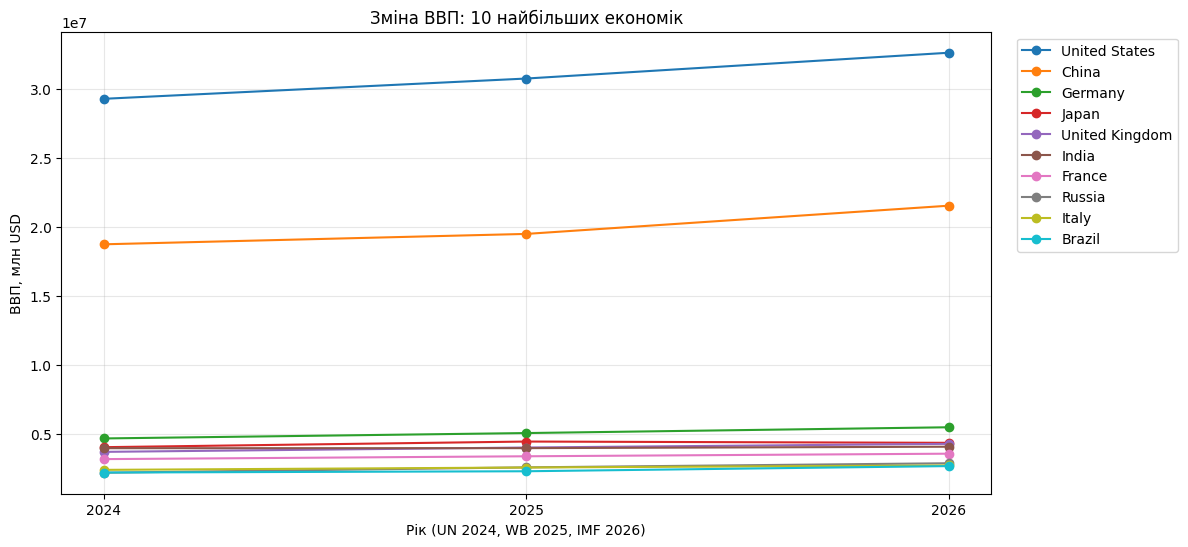

Стабільне зростання: 189 країн, стабільний спад: 4 країн
Зростання (топ-10 за ВВП): United States, China, Germany, United Kingdom, India, France, Russia, Italy, Brazil, Canada
Спад (топ-10 за ВВП): Iran, Iraq, Qatar, Kuwait


In [ ]:
order = ["United Nations (2024)", "World Bank (2025)", "IMF (2026)"]
years = ["2024", "2025", "2026"]

top10 = df.nlargest(10, "IMF (2026)")
plt.figure(figsize=(12, 6))
for _, r in top10.iterrows():
    plt.plot(years, r[order].astype(float).values, marker="o", label=r["Country"])
plt.title("Зміна ВВП: 10 найбільших економік")
plt.xlabel("Рік (UN 2024, WB 2025, IMF 2026)")
plt.ylabel("ВВП, млн USD")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.show()

growth = df[(df[order[0]] < df[order[1]]) & (df[order[1]] < df[order[2]])]
decline = df[(df[order[0]] > df[order[1]]) & (df[order[1]] > df[order[2]])]
print(f"Стабільне зростання: {len(growth)} країн, стабільний спад: {len(decline)} країн")
print("Зростання (топ-10 за ВВП):", ", ".join(growth.nlargest(10, "IMF (2026)")["Country"]))
print("Спад (топ-10 за ВВП):", ", ".join(decline.nlargest(10, "IMF (2026)")["Country"]) or "—")